# EE-411 - Fundamentals of Inference and Learning
## Exercise Session 10 - Principal Component Analysis

**Learning objectives**
- Explain how PCA identifies directions of maximal variance.
- Use PCA for dimensionality reduction and noise filtering.
- Apply PCA to face images and compare nearest-neighbour classification in the original and projected spaces.

**Prerequisites**
- Lecture concepts: covariance, eigenvectors, variance, and dimensionality reduction.
- Python packages: NumPy, Matplotlib, SciPy, and scikit-learn. The LFW faces dataset is fetched by scikit-learn.


In [204]:
#We import th usual packages
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as sla

## Introducing PCA

_This exercise relies heavily on an example taken from the Python Data Science Handbook, by Jake VanderPlas_

Principal component analysis is a fast and flexible unsupervised method for dimensionality reduction in data.

 Its behavior is easier to visualize by looking at a two-dimensional dataset. 
 
 Let's consider the following 200 points in a 2D plane:

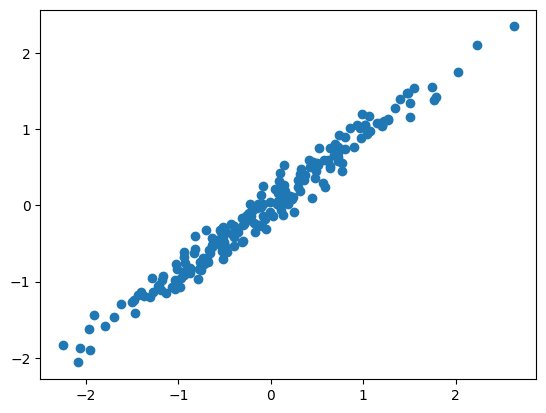

In [205]:
rng = np.random.RandomState(0) #initialize seed
X = np.dot(rng.rand(2, 2), rng.randn(2, 200)).T
plt.scatter(X[:, 0], X[:, 1]);

By eye, it is clear that there is a nearly linear relationship between the x and y variables, but the problem setting here is slightly different from the usual linear regression: rather than attempting to predict the y values from the x values, the unsupervised learning problem attempts to learn about the relationship between the x and y values.

In PCA, this relationship is quantified by finding a list of the principal axes in the data, and using those axes to describe the dataset.

In [206]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca.fit(X)

,n_components,2
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


Giving the dataset to the function `fit`, the model learns some quantities from the data, most importantly tha *components* and the *explained variance*:



In [207]:
pca.components_

array([[ 0.739393  ,  0.67327408],
       [-0.67327408,  0.739393  ]])

In [208]:
pca.explained_variance_

array([1.48668691, 0.01057775])

To see what these numbers mean, let's visualize them as vectors over the input data, using the "components" to define the direction of the vector, and the "explained variance" to define the squared-length of the vector:

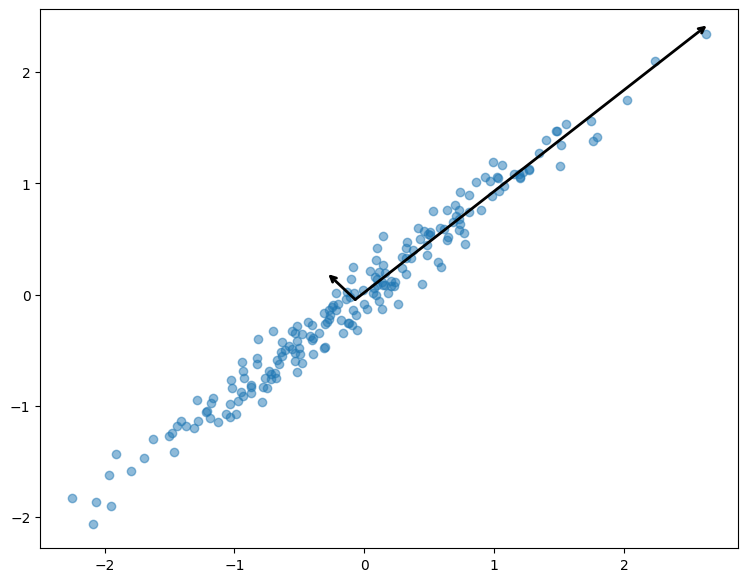

In [209]:
#to draw a vector going from the point v0 to the point v1
def draw_vector(v0, v1, ax=None):
    ax = ax or plt.gca()
    arrowprops=dict(arrowstyle='->',
                    linewidth=2,
                    shrinkA=0, shrinkB=0)
    ax.annotate('', v1, v0, arrowprops=arrowprops)

plt.figure(figsize=(9,7))
plt.scatter(X[:, 0], X[:, 1], alpha=0.5)
for length, vector in zip(pca.explained_variance_, pca.components_):
    v = vector * 3 * np.sqrt(length)
    draw_vector(pca.mean_, pca.mean_ + v)


These vectors represent the principal axes of the data, and the length of the vector is an indication of how "important" that axis is in describing the distribution of the data—more precisely, it is a measure of the variance of the data when projected onto that axis. The projection of each data point onto the principal axes are the "principal components" of the data.

## Dimensionality reduction 

Using PCA for dimensionality reduction involves zeroing out one or more of the smallest principal components, resulting in a lower-dimensional projection of the data that preserves the maximal data variance.

Here is an example of using PCA as a dimensionality reduction transform, using the same data as before:

In [210]:
pca = PCA(n_components=1)
pca.fit(X)
X_pca = pca.transform(X)
print("original shape:   ", X.shape)
print("transformed shape:", X_pca.shape)

original shape:    (200, 2)
transformed shape: (200, 1)


The transformed data has been reduced to a single dimension. To understand the effect of this dimensionality reduction, we can perform the inverse transform of this reduced data and plot it along with the original data:

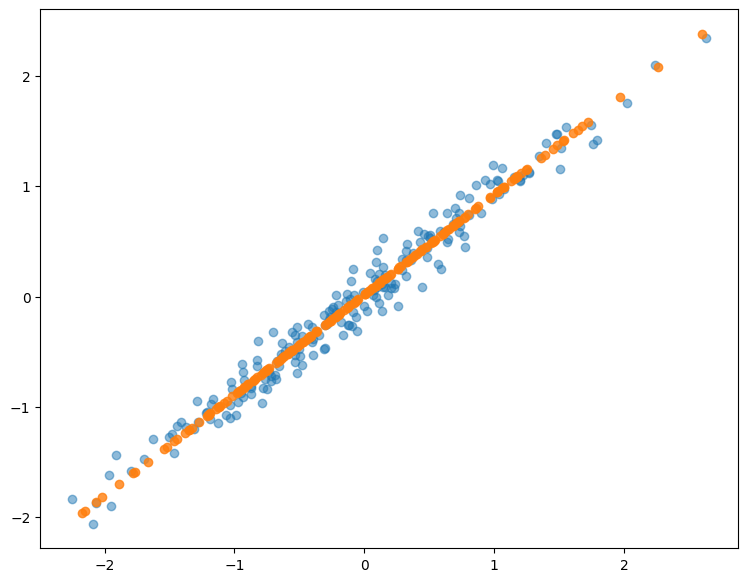

In [211]:
X_new = pca.inverse_transform(X_pca)
plt.figure(figsize=(9,7))
plt.scatter(X[:, 0], X[:, 1], alpha=0.5)
plt.scatter(X_new[:, 0], X_new[:, 1], alpha=0.8)

This makes clear what a PCA dimensionality reduction means: the information along the least important principal axis or axes is removed, leaving only the component(s) of the data with the highest variance. The fraction of variance that is cut out (proportional to the spread of points about the line formed in this figure) is roughly a measure of how much "information" is discarded in this reduction of dimensionality.

This reduced-dimension dataset is in some senses "good enough" to encode the most important relationships between the points: despite reducing the dimension of the data by 50%, the overall relationship between the data points are mostly preserved.

## PCA for noise filtering

PCA can also be used as a filtering approach for noisy data. The idea is this: any components with variance much larger than the effect of the noise should be relatively unaffected by the noise. So if you reconstruct the data using just the largest subset of principal components, you should be preferentially keeping the signal and throwing out the noise.

Let's see how this looks with the digits data. First we will plot several of the input noise-free data:

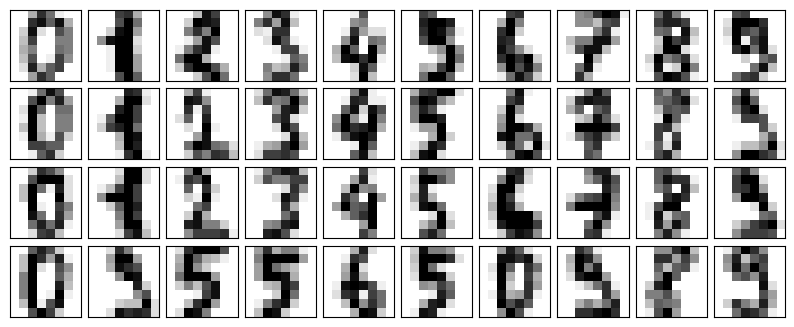

In [212]:
from sklearn.datasets import load_digits
digits = load_digits()
digits.data.shape

def plot_digits(data):
    fig, axes = plt.subplots(4, 10, figsize=(10, 4),
                             subplot_kw={'xticks':[], 'yticks':[]},
                             gridspec_kw=dict(hspace=0.1, wspace=0.1))
    for i, ax in enumerate(axes.flat):
        ax.imshow(data[i].reshape(8, 8),
                  cmap='binary', interpolation='nearest',
                  clim=(0, 16))
plot_digits(digits.data)

Now lets add some random noise to create a noisy dataset, and re-plot it:

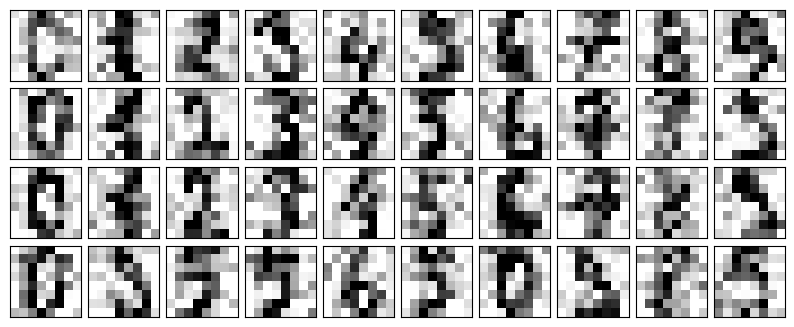

In [213]:
np.random.seed(42)
noisy = np.random.normal(digits.data, 4)
plot_digits(noisy)

It's clear by eye that the images are noisy, and contain spurious pixels. Let's train a PCA on the noisy data, requesting that the projection preserve 50% of the variance:

In [214]:
pca = PCA(0.50).fit(noisy)
pca.n_components_

np.int64(12)

Here 50% of the variance amounts to 12 principal components. Now we compute these components, and then use the inverse of the transform to reconstruct the filtered digits:

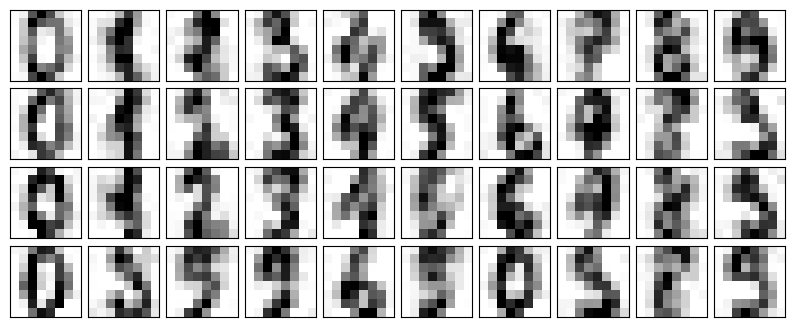

In [215]:
components = pca.transform(noisy)
filtered = pca.inverse_transform(components)
plot_digits(filtered)

A vital part of using PCA in practice is the ability to estimate how many components are needed to describe the data. This can be determined by looking at the `cumulative explained variance ratio` as a function of the number of components:

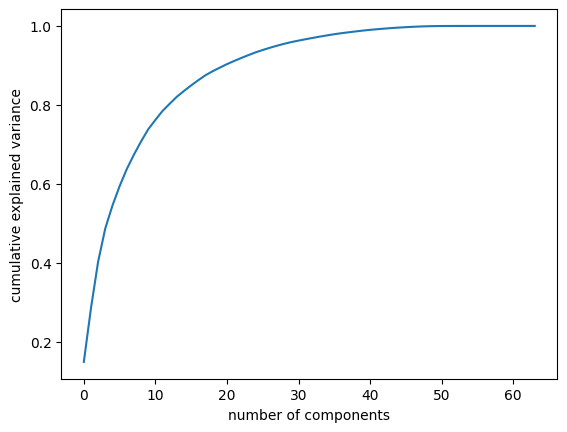

In [216]:
pca = PCA().fit(digits.data)
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance');

This curve quantifies how much of the total, 64-dimensional variance is contained within the first N components. For example, we see that with the digits the first 10 components contain approximately 75% of the variance, while you need around 50 components to describe close to 100% of the variance.

### Your turn: Eigenfaces

Download the *Labelled Faces in the Wild* (LFW) people dataset from sklearn. This dataset is a collection of pictures of famous people faces. 

By setting `min_faces_per_person=30`, the extracted dataset will only retain pictures of people that have at least 30 different pictures. 

In [217]:
from sklearn.datasets import fetch_lfw_people

In [218]:
# Download the dataset

min_faces_per_person = 30

faces = fetch_lfw_people(min_faces_per_person=min_faces_per_person)

Now we plot the first 10 faces (`dataset.target_images`) together with the corresponding names (`dataset.target_names`) using
`imshow`

George W Bush


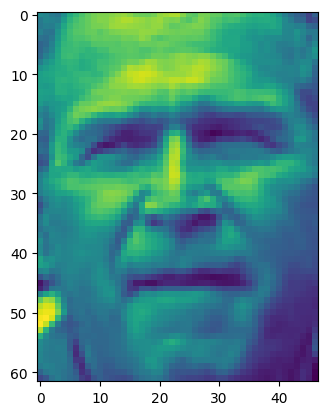

Arnold Schwarzenegger


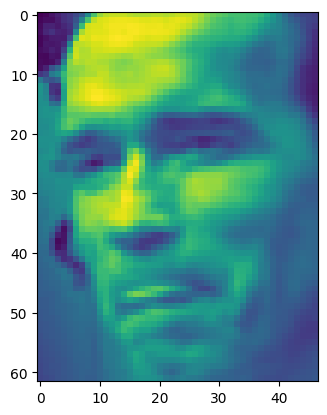

Laura Bush


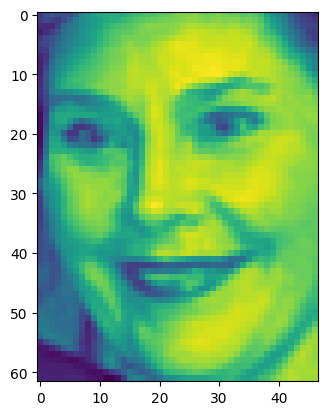

George W Bush


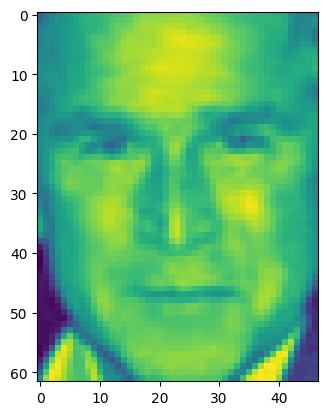

George W Bush


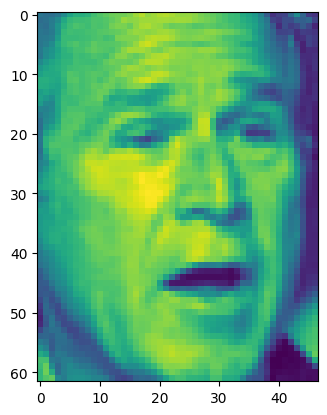

Nestor Kirchner


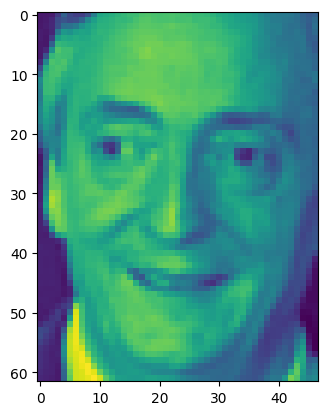

Arnold Schwarzenegger


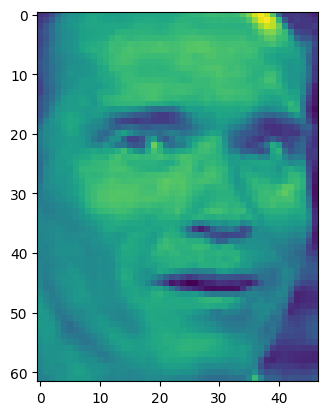

Lleyton Hewitt


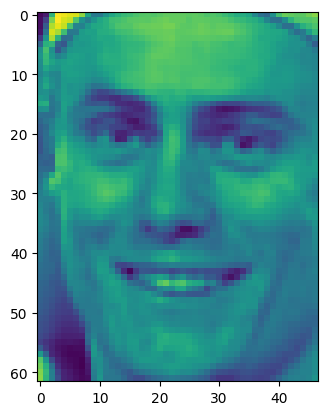

Colin Powell


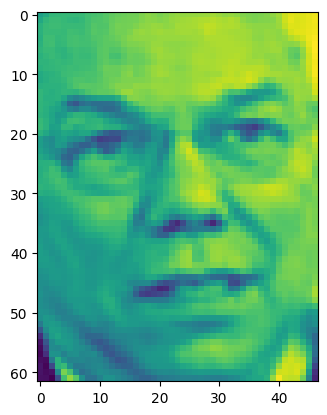

Lleyton Hewitt


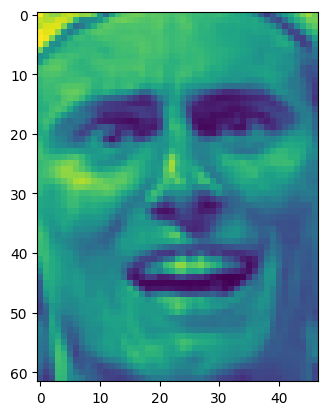

In [219]:
# Print the first 10 faces with the corresponding names

for X, y in zip(faces.images[:10], faces.target[:10]):
    
    print(faces.target_names[y])
    plt.imshow(X)
    plt.show()

In [220]:
print(f"There are {len(faces.data)} images in total, each composed by {len(faces.data[0])} pixels")

There are 2370 images in total, each composed by 2914 pixels


### Exercise 1 - Prepare a balanced face dataset

Keep 30 pictures per person to obtain a balanced dataset. Normalize the pixel values to the range [0, 1].

In [221]:
# TODO: complete the exercise described above
# YOUR CODE HERE
SEED = 13
np.random.seed(SEED)

X_new = []
y_new = []

for target in np.unique(faces.target):
    # Find indices of all images for the target
    target_indices = np.where(faces.target == target)[0]
    # Shuffle the indices and keep 30 indices only for the target
    np.random.shuffle(target_indices)
    keep_indices = target_indices[:30]

    # Put the chosen images and label in the new lists
    X_new.append(faces.data[keep_indices])
    y_new.append(faces.target[keep_indices])

# Put all the images and labels in a single array
X, y = np.concatenate(X_new), np.concatenate(y_new)

print("Range of pixels:", X.min(), "to", X.max())

print(f"Now there are {len(X)} images.")

Range of pixels: 0.0 to 1.0
Now there are 1020 images.


### Exercise 2 - Fit PCA to the face dataset

Fit PCA to the normalized data, then print the shape of the principal components.

In [222]:
# TODO: complete the exercise described above
# YOUR CODE HERE
pca = PCA().fit(X)
pca.components_.shape

(1020, 2914)

### Exercise 3 - Visualize principal components

Use `imshow` to plot the first five principal components. Describe what they look like.

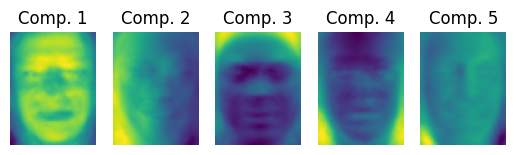

In [223]:
# TODO: complete the exercise described above
# YOUR CODE HERE
five_components = PCA(n_components=5).fit(X)

# Retrieve image size
img_shape = faces.images[0].shape

# Plot the 5 first principal components
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(five_components.components_[i].reshape(img_shape))
    plt.title(f'Comp. {i + 1}')
    plt.axis('off')
plt.show()

*Answer*

Some of them define the contour of the face better and some of them define the features within the face better.

### Exercise 4 - Explained variance

Plot the cumulative explained variance. From the plot, estimate how many components are needed to explain most of the variance in the face dataset.

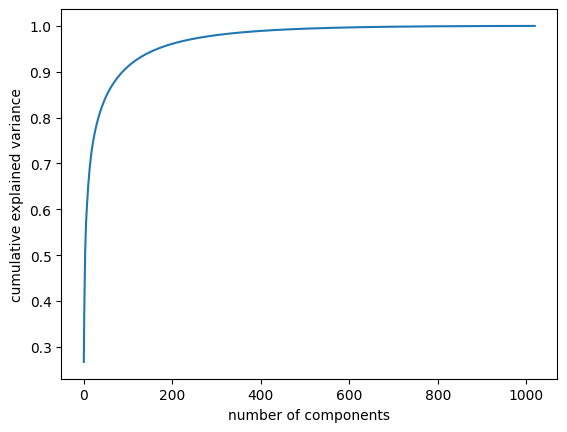

In [225]:
# TODO: complete the exercise described above
# YOUR CODE HERE
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.plot(cumulative_variance)
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance');

*Answer*

We need around 500 components to explain almost 100% of the variance in this dataset. 200 components explain around 95% of the variance in the dataset.

## Evaluated question

### Exercise 5 - Reconstruct faces

For each of 10, 30, 100, 300, and 1,000 components, reconstruct four face images using `inverse_transform`. Plot and compare the reconstructions.

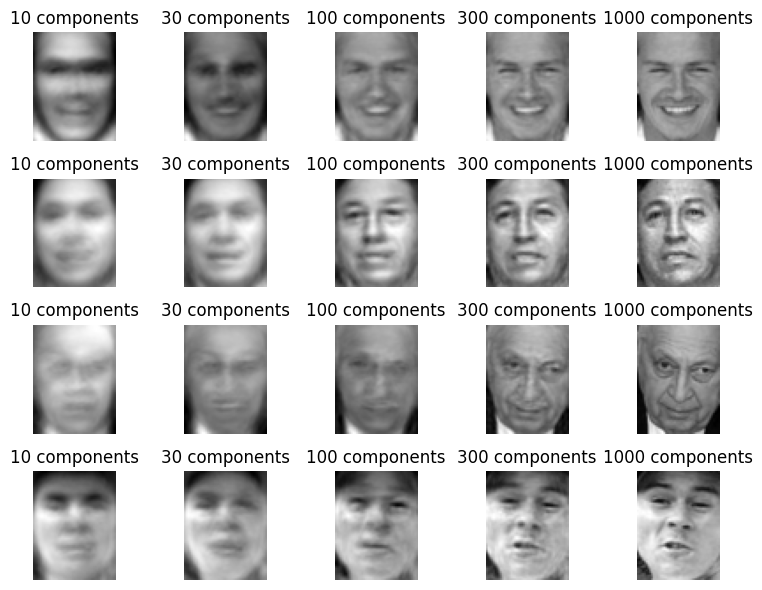

In [226]:
# TODO: complete the exercise described above
# YOUR CODE HERE
def reconstruct_image(image, n_components):
    # Retrieve the n_components PCA components
    pca = PCA(n_components=n_components)
    pca.fit(X)
    components = pca.transform(image.reshape(1, -1))

    # Use the inverse transform to reconstruct the image from the components
    reconstructed_image = pca.inverse_transform(components)

    return reconstructed_image.reshape(faces.images[0].shape)

n_components_list = [10, 30, 100, 300, 1000]
images_to_reconstruct = np.random.choice(len(X), size=4, replace=False)  # Choose 4 images to reconstruct

fig, axes = plt.subplots(len(images_to_reconstruct), len(n_components_list), figsize=(8, 6))

for row, image_index in enumerate(images_to_reconstruct):
    for col, n_components in enumerate(n_components_list):
        # Reconstruct the image using n_components
        reconstructed = reconstruct_image(X[image_index], n_components)

        # Display the reconstructed image
        axes[row, col].imshow(reconstructed, cmap='gray')
        axes[row, col].set_title(f'{n_components} components')
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()

*Answer*

By plotting the reconstruction for 4 different images we observe that until 300 components the face is very blurry. With 300 components we already can recognize the face really well and by using 1000 components it's even clearer.

### Now, we are going to compare the performance of a naive classifier (the predicted label corresponds to the label of the nearest-neighbour image) when using the full pictures and the first 100 PCA projections.

### Exercise 6 - Split the data

Split the face data into training and test sets.

In [227]:
# TODO: complete the exercise described above
# YOUR CODE HERE
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")

Training set size: 816
Test set size: 204


### Exercise 7 - Classify in the original space

Fit `sklearn.neighbors.KNeighborsClassifier` with `n_neighbors=1` on the training images. Evaluate accuracy with `score` on the test set.

In [228]:
# TODO: complete the exercise described above
# YOUR CODE HERE
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train, y_train)

score_knn = knn.score(X_test, y_test)
print(f"Accuracy on the test set: {score_knn:.4f}")
print(f"Accuracy on the training set: {knn.score(X_train, y_train):.4f}")

Accuracy on the test set: 0.2304
Accuracy on the training set: 1.0000


### Exercise 8 - Classify in the PCA space

Repeat the training using the first 100 principal components. Project both training and test sets before fitting and scoring. Compare the accuracy with Exercise 7.

In [229]:
# TODO: complete the exercise described above
# YOUR CODE HERE
# Setup PCA with 100 components
pca_100 = PCA(n_components=100)

# Transform the training and test sets
X_train_pca = pca_100.fit_transform(X_train)
X_test_pca = pca_100.transform(X_test)

# Fit the KNN classifier on the transformed training set
knn_pca = KNeighborsClassifier(n_neighbors=1)
knn_pca.fit(X_train_pca, y_train)

# Evaluate on test set
score_knn_pca = knn_pca.score(X_test_pca, y_test)
print(f"Accuracy on the test set: {score_knn_pca:.4f}")
print(f"Accuracy on the training set: {knn_pca.score(X_train_pca, y_train):.4f}")


Accuracy on the test set: 0.2647
Accuracy on the training set: 1.0000


*Answer*

We observe that the accuracy has increased by almost 3 points.

### Exercise 9 - Evaluate whitening

Set `whiten=True` when fitting PCA. Whitening rescales the principal components to unit variance. Reclassify the faces and compare the accuracy with Exercises 7 and 8.

Set `whiten=True` when fitting PCA. Whitening rescales the principal components to unit variance. Reclassify the faces and compare the accuracy with Exercises 7 and 8.

In [230]:
# TODO: complete the exercise described above
# YOUR CODE HERE
# Setup PCA with 100 components
pca_100 = PCA(n_components=100, whiten=True)

# Transform the training and test sets
X_train_pca = pca_100.fit_transform(X_train)
X_test_pca = pca_100.transform(X_test)

# Fit the KNN classifier on the transformed training set
knn_pca_whiten = KNeighborsClassifier(n_neighbors=1)
knn_pca_whiten.fit(X_train_pca, y_train)

# Evaluate on test set
score_knn_pca_whiten = knn_pca_whiten.score(X_test_pca, y_test)
print(f"Accuracy on the test set: {score_knn_pca_whiten:.4f}")
print(f"Accuracy on the training set: {knn_pca_whiten.score(X_train_pca, y_train):.4f}")

Accuracy on the test set: 0.3578
Accuracy on the training set: 1.0000


*Answer*

We observe that the accuracy has increased by almost 12 points from exercise 7 and has increased by almost 9 points from exercise 8. Even though we can still see that the accuracy is not that high. We observe that some overfitting is probably happening as the training accuracy is 1.